# A1. 언어 모델과 샘플링: 다음 토큰을 어떻게 고르나

- 영상: [3:57 What is a language model?](https://www.youtube.com/watch?v=Vr1NzH8bT44&t=237s), [7:46 Sampling](https://www.youtube.com/watch?v=Vr1NzH8bT44&t=466s) ~ 16:03 [2]
- 슬라이드: `data/lecture02.pdf` 6–23쪽 [1]

## 목표

1. 언어 모델이 내놓는 것이 "다음 토큰의 확률표"라는 것을 직접 확인합니다.
2. 문장 전체의 확률이 "토큰마다의 조건부 확률을 곱한 값"이라는 것을 계산으로 확인합니다.
3. 다음 토큰을 고르는 방법(greedy, temperature, top-k, top-p, beam search)을 직접 짜고, Hugging Face 결과와 맞춰 봅니다.

**이 노트북이 답하는 질문**: 언어 모델은 무엇을 내놓고, 우리는 그 안에서 다음 말을 어떻게 고르나?

**읽는 법**: 개념 하나마다 같은 순서로 설명합니다.
한 줄 정의 → 왜 필요한가 → 숫자로 따라가기 → 그림 → 그림에서 볼 것 → 식과 근거 → 직접 바꿔 보기.
문장 끝의 `[3]` 같은 번호는 맨 아래 **출처** 절의 번호입니다.

모델은 GPT-2 small(파라미터 약 1억 2천만 개)을 씁니다. 작아서 CPU에서도 돌아갑니다.

In [1]:
import os, warnings
os.environ["TRANSFORMERS_VERBOSITY"] = "error"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["HF_HUB_VERBOSITY"] = "error"
warnings.filterwarnings("ignore")          # 설치 환경에 따라 나오는 경고 문구를 숨긴다

import math
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForCausalLM

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(0)
tok = AutoTokenizer.from_pretrained("openai-community/gpt2")
model = AutoModelForCausalLM.from_pretrained("openai-community/gpt2").to(device).eval()
print("device:", device)

device: cpu


In [2]:
# 그림 도구 모음입니다. 펼쳐 보지 않아도 됩니다. 본문은 draw_xxx() 를 한 줄씩 부릅니다.
# 팔레트: Okabe-Ito (색약에도 구별되는 8색). 그림 안 글자는 영어로 씁니다.
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Rectangle, Ellipse

plt.rcParams.update({"font.size": 10, "axes.titlesize": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 100})
C = dict(orange="#E69F00", sky="#56B4E9", green="#009E73", yellow="#F0E442",
         blue="#0072B2", red="#D55E00", purple="#CC79A7", black="#000000", grey="#BBBBBB")


def _box(ax, x, y, text, w=1.7, h=0.62, fc="#FFFFFF", ec="#000000", fs=9.5):
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.03",
                                fc=fc, ec=ec, lw=1))
    ax.text(x, y, text, ha="center", va="center", fontsize=fs)


def _arrow(ax, x1, y1, x2, y2, color="#000000", text=None, fs=8.5, rad=0.0, dy=0.1):
    ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle="-|>", mutation_scale=12,
                                 color=color, lw=1, connectionstyle=f"arc3,rad={rad}"))
    if text:
        ax.text((x1 + x2) / 2, (y1 + y2) / 2 + dy, text, ha="center", va="bottom", fontsize=fs, color=color)


def draw_concept_map():
    fig, ax = plt.subplots(figsize=(12, 3.6))
    top = [("text", 0, C["grey"], ""), ("tokenizer", 2.3, C["sky"], "1-1"), ("token IDs", 4.6, C["grey"], "1-1"),
           ("GPT-2", 6.9, C["blue"], ""), ("logits\n(50,257 scores)", 9.2, C["grey"], "1-2")]
    bot = [("softmax", 9.2, C["sky"], "1-2"), ("probabilities", 6.9, C["grey"], "1-2, 1-3, 1-4"),
           ("decoding rule\ngreedy / T / top-k\ntop-p / beam", 4.6, C["orange"], "2"),
           ("next token", 2.3, C["grey"], "2")]
    for row, y in [(top, 1.6), (bot, 0)]:
        for name, x, col, sec in row:
            _box(ax, x, y, name, w=1.9, h=0.8 if "\n" in name else 0.62, fc=col + "55")
            if sec:
                ax.text(x, y - 0.55 if y == 1.6 else y - 0.68, f"section {sec}", ha="center", va="top",
                        fontsize=8.5, color="#555555")
    for (a, b) in zip(top[:-1], top[1:]):
        _arrow(ax, a[1] + 0.97, 1.6, b[1] - 0.97, 1.6)
    _arrow(ax, 9.2, 1.18, 9.2, 0.42)
    for (a, b) in zip(bot[:-1], bot[1:]):
        _arrow(ax, a[1] - 0.97, 0, b[1] + 0.97, 0)
    _arrow(ax, 2.3, 0.33, 4.3, 1.27, color=C["red"], rad=-0.25)
    ax.text(3.45, 0.62, "append, repeat", ha="left", va="center", fontsize=9, color=C["red"])
    ax.set_xlim(-1.1, 10.4); ax.set_ylim(-1.1, 2.2); ax.axis("off")
    ax.set_title("A1 concept map: from text to the next token")
    plt.show()


def draw_tokens(rows):
    """rows = [(label, [(token_string, id), ...]), ...]"""
    fig, ax = plt.subplots(figsize=(12, 0.95 * len(rows) + 0.4))
    for r, (label, toks) in enumerate(rows):
        y = -r * 1.0
        ax.text(-0.2, y, label, ha="right", va="center", fontsize=9.5)
        x = 0.0
        for i, (s, tid) in enumerate(toks):
            w = max(0.75, 0.13 * len(s) + 0.35)
            ax.add_patch(Rectangle((x, y - 0.25), w, 0.5, fc=[C["sky"], C["orange"]][i % 2] + "66", ec="black", lw=0.8))
            ax.text(x + w / 2, y, s, ha="center", va="center", fontsize=9.5)
            ax.text(x + w / 2, y - 0.33, str(tid), ha="center", va="top", fontsize=8.5, color="#444444")
            x += w + 0.08
        ax.text(x + 0.15, y, f"{len(toks)} tokens", ha="left", va="center", fontsize=9, color=C["red"])
    ax.set_xlim(-4.2, 12.5); ax.set_ylim(-len(rows) + 0.3, 0.55); ax.axis("off")
    ax.set_title("How the GPT-2 tokenizer cuts text ('·' marks a leading space; small number = token ID)")
    plt.show()


def draw_softmax_steps(logits, labels):
    z = np.asarray(logits, float); e = np.exp(z); p = e / e.sum()
    fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
    for a, vals, title, col, fmt in [(ax[0], z, "1. logits (any real number)", C["grey"], "{:.1f}"),
                                     (ax[1], e, "2. exp(logit) (always > 0)", C["sky"], "{:.2f}"),
                                     (ax[2], p, "3. divide by the sum -> probability", C["blue"], "{:.3f}")]:
        bars = a.bar(labels, vals, color=col)
        a.axhline(0, color="black", lw=0.8)
        for b_, v in zip(bars, vals):
            a.text(b_.get_x() + b_.get_width() / 2, v + (0.02 * max(abs(vals).max(), 1) if v >= 0 else -0.02 * abs(vals).max()),
                   fmt.format(v), ha="center", va="bottom" if v >= 0 else "top", fontsize=8.5)
        a.set_title(title)
        a.set_ylim(min(0, vals.min()) * 1.3 - 0.05, vals.max() * 1.25)
    ax[1].text(0.97, 0.95, f"sum = {e.sum():.2f}", transform=ax[1].transAxes, ha="right", va="top", fontsize=9)
    ax[2].text(0.97, 0.95, f"sum = {p.sum():.2f}", transform=ax[2].transAxes, ha="right", va="top", fontsize=9)
    fig.tight_layout(); plt.show()


def draw_next_token_dist(tokens, probs, rest_mass, title):
    fig, ax = plt.subplots(figsize=(10, 3.4))
    ax.bar(range(len(tokens)), probs, color=C["blue"])
    ax.set_xticks(range(len(tokens)), tokens, rotation=45, ha="right")
    for i, v in enumerate(probs):
        ax.text(i, v + 0.004, f"{v:.3f}", ha="center", va="bottom", fontsize=8.5)
    ax.set_ylabel("P(next token)")
    ax.set_title(title)
    ax.text(0.98, 0.9, f"all other tokens together: {rest_mass:.2f}", transform=ax.transAxes,
            ha="right", va="top", fontsize=9.5, color=C["red"])
    ax.set_ylim(0, max(probs) * 1.2)
    fig.tight_layout(); plt.show()


def draw_log_prob():
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
    p = np.linspace(0.001, 1, 400)
    ax[0].plot(p, np.log(p), color=C["blue"])
    for v in [0.5, 0.1, 0.0124]:
        ax[0].plot(v, np.log(v), "o", color=C["red"])
        ax[0].annotate(f"p = {v}\nlog p = {np.log(v):.2f}", (v, np.log(v)), textcoords="offset points",
                       xytext=(14, -6), fontsize=8.5)
    ax[0].set_xlabel("probability p"); ax[0].set_ylabel("natural log  ln p")
    ax[0].set_title("A. log turns (0, 1] into (-inf, 0]")
    n = np.arange(1, 81)
    prod32 = np.cumprod(np.full(80, 0.1, dtype=np.float32))
    shown = np.where(prod32 > 0, prod32, np.nan)
    ax[1].semilogy(n, shown, "o-", ms=3, color=C["orange"], label="product of probabilities (float32)")
    first0 = int(n[prod32 == 0][0])
    ax[1].axvline(first0, ls="--", color=C["red"], lw=1)
    ax[1].text(first0 + 1, 1e-20, f"becomes exactly 0\nafter {first0} tokens\n(underflow)", fontsize=8.5,
               color=C["red"], va="center")
    ax2 = ax[1].twinx()
    ax2.plot(n, n * np.log(0.1), color=C["blue"], label="sum of log probabilities")
    ax2.set_ylabel("sum of ln p", color=C["blue"])
    ax2.spines["right"].set_visible(True)
    ax[1].set_xlabel("number of tokens (each p = 0.1)"); ax[1].set_ylabel("product (log axis)", color=C["orange"])
    ax[1].set_title("B. multiplying shrinks to 0, adding logs does not")
    fig.tight_layout(); plt.show()


def draw_chain_rule(tokens, cond_probs):
    cond_probs = np.asarray(cond_probs)
    cum = np.cumprod(cond_probs)
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
    x = np.arange(len(tokens))
    ax[0].bar(x, cond_probs, color=C["sky"])
    ax[0].set_yscale("log")
    for i, v in enumerate(cond_probs):
        ax[0].text(i, v * 1.4, f"{v:.4f}" if v >= 1e-3 else f"{v:.1e}", ha="center", va="bottom", fontsize=8.5)
    ax[0].set_xticks(x, tokens)
    ax[0].set_ylim(cond_probs.min() / 5, 3)
    ax[0].set_ylabel("P(token | tokens before it)")
    ax[0].set_title("A. one conditional probability per token")
    ax[1].plot(x, cum, "o-", color=C["red"])
    ax[1].set_yscale("log")
    for i, v in enumerate(cum):
        ax[1].text(i, v * 2.2, f"{v:.1e}", ha="center", va="bottom", fontsize=8.5)
    ax[1].set_xticks(x, tokens)
    ax[1].set_ylim(cum.min() / 20, 3)
    ax[1].set_ylabel("product so far = P(sentence up to here)")
    ax[1].set_title("B. multiply them left to right")
    fig.tight_layout(); plt.show()


def draw_gen_vs_disc(seed=0):
    rng = np.random.default_rng(seed)
    m0, m1, s = np.array([-1.0, -0.5]), np.array([1.2, 0.8]), 0.7
    X = np.vstack([rng.normal(m0, s, (60, 2)), rng.normal(m1, s, (60, 2))])
    y = np.r_[np.zeros(60), np.ones(60)]
    # 판별 모델: 로지스틱 회귀를 경사 하강으로 맞춘다 (P(y | x) 만 배운다)
    w, b = np.zeros(2), 0.0
    for _ in range(3000):
        pr = 1 / (1 + np.exp(-(X @ w + b)))
        w -= 0.1 * X.T @ (pr - y) / len(y); b -= 0.1 * (pr - y).mean()
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
    for a in ax:
        a.scatter(*X[y == 0].T, s=14, color=C["sky"], label="class A")
        a.scatter(*X[y == 1].T, s=14, color=C["orange"], label="class B")
        a.set_xlim(-3.5, 3.8); a.set_ylim(-3, 3.2); a.set_aspect("equal")
        a.set_xlabel("feature 1"); a.set_ylabel("feature 2")
    xs = np.linspace(-3.5, 3.8, 10)
    ax[0].plot(xs, -(w[0] * xs + b) / w[1], color="black", lw=1.5, label="learned boundary")
    ax[0].set_title("A. discriminative: learns P(label | x)\n-> a boundary, cannot make new x")
    ax[0].legend(loc="upper left", fontsize=8.5, frameon=False)
    # 생성 모델: 무리마다 평균과 퍼짐(분포)을 배운다 (P(x) 를 배운다) -> 새 점을 뽑을 수 있다
    for cls, col in [(0, C["sky"]), (1, C["orange"])]:
        mu, sd = X[y == cls].mean(0), X[y == cls].std(0)
        for k in [1, 2]:
            ax[1].add_patch(Ellipse(mu, 2 * k * sd[0], 2 * k * sd[1], fill=False, ec=col, lw=1.2))
        new = rng.normal(mu, sd, (5, 2))
        ax[1].scatter(*new.T, marker="*", s=130, color=col, ec="black", lw=0.5, zorder=3)
    ax[1].scatter([], [], marker="*", s=130, color="white", ec="black", label="NEW points sampled")
    ax[1].set_title("B. generative: learns P(x) (here, per class)\n-> can sample new x")
    ax[1].legend(loc="upper left", fontsize=8.5, frameon=False)
    fig.tight_layout(); plt.show()


def draw_greedy_vs_sample(labels, probs, n_draw=1000, seed=0):
    probs = np.asarray(probs, float)
    rng = np.random.default_rng(seed)
    draws = rng.choice(len(probs), size=n_draw, p=probs)
    freq = np.bincount(draws, minlength=len(probs)) / n_draw
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
    cols = [C["red"] if i == probs.argmax() else C["grey"] for i in range(len(probs))]
    ax[0].bar(labels, probs, color=cols)
    ax[0].set_title("A. greedy: always take the tallest bar")
    ax[0].set_ylabel("probability")
    ax[1].bar(np.arange(len(probs)) - 0.2, probs, width=0.4, color=C["blue"], label="model probability")
    ax[1].bar(np.arange(len(probs)) + 0.2, freq, width=0.4, color=C["orange"], label=f"share of {n_draw} random draws")
    ax[1].set_xticks(range(len(probs)), labels)
    ax[1].set_title("B. sampling: pick at random, in proportion")
    ax[1].legend(fontsize=8.5, frameon=False)
    fig.tight_layout(); plt.show()


def draw_temperature(logits, labels, temps=(0.5, 1.0, 2.0)):
    z = np.asarray(logits, float)
    fig, ax = plt.subplots(1, len(temps), figsize=(12, 3.3), sharey=True)
    for a, T, col in zip(ax, temps, [C["red"], C["blue"], C["green"]]):
        p = np.exp(z / T); p /= p.sum()
        a.bar(labels, p, color=col)
        for i, v in enumerate(p):
            a.text(i, v + 0.01, f"{v:.2f}", ha="center", va="bottom", fontsize=8.5)
        a.set_title(f"T = {T}: softmax(logits / {T})")
    ax[0].set_ylabel("probability"); ax[0].set_ylim(0, 1.0)
    fig.tight_layout(); plt.show()


def draw_topk_topp(labels, probs, k=3, p=0.9):
    probs = np.asarray(probs, float)
    order = np.argsort(-probs); ps = probs[order]; ls = [labels[i] for i in order]
    cum = np.cumsum(ps)
    n_p = int(np.searchsorted(cum, p) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
    x = np.arange(len(ps))
    keep_k = x < k
    ax[0].bar(x, ps, color=np.where(keep_k, C["blue"], C["grey"]))
    renorm = np.where(keep_k, ps / ps[keep_k].sum(), 0)
    ax[0].plot(x[keep_k], renorm[keep_k], "D", color=C["orange"], label="after renormalising (sum = 1)")
    ax[0].axvline(k - 0.5, ls="--", color=C["red"])
    ax[0].text(k - 0.4, 0.9 * max(renorm.max(), ps.max()), f"cut after k = {k}", color=C["red"], fontsize=9)
    ax[0].set_xticks(x, ls); ax[0].set_ylabel("probability")
    ax[0].set_title(f"A. top-k (k = {k}): keep the {k} largest")
    ax[0].legend(fontsize=8.5, frameon=False, loc="center right")
    ax[1].bar(x, ps, color=np.where(x < n_p, C["blue"], C["grey"]))
    ax[1].plot(x, cum, "o-", color=C["purple"], label="running total")
    ax[1].axhline(p, ls=":", color=C["red"])
    ax[1].text(len(ps) - 0.5, p + 0.02, f"p = {p}", color=C["red"], ha="right", fontsize=9)
    ax[1].axvline(n_p - 0.5, ls="--", color=C["red"])
    ax[1].set_xticks(x, ls); ax[1].set_ylim(0, 1.08)
    ax[1].set_title(f"B. top-p (p = {p}): smallest set whose total reaches p ({n_p} tokens here)")
    ax[1].legend(fontsize=8.5, frameon=False, loc="center right")
    fig.tight_layout(); plt.show()


def draw_topp_contexts(items, p=0.9):
    """items = [(prompt, sorted_probs ndarray), ...]  누적 확률을 순위(로그 눈금)에 따라 그린다"""
    fig, ax = plt.subplots(1, len(items), figsize=(12, 3.6), sharey=True)
    for a, (prompt, ps) in zip(ax, items):
        cum = np.cumsum(ps)
        n_p = int(np.searchsorted(cum, p) + 1)
        x = np.arange(1, len(ps) + 1)
        a.plot(x, cum, color=C["purple"], label="running total of probabilities")
        a.axvspan(0.8, n_p, color=C["blue"], alpha=0.2, label="tokens top-p keeps")
        a.axhline(p, ls=":", color=C["red"]); a.axvline(n_p, ls="--", color=C["red"])
        a.text(n_p * 1.3, 0.3, f"keeps {n_p:,} token{'s' if n_p > 1 else ''}", color=C["red"], fontsize=9.5)
        a.text(1.2, 0.8, f"top-1 token alone: {ps[0]:.2f}", fontsize=9, va="top")
        a.set_xscale("log"); a.set_xlim(0.8, len(ps)); a.set_ylim(0, 1.03)
        a.set_title(f"'{prompt} ...'")
        a.set_xlabel("token rank, largest first (log axis)")
    ax[0].set_ylabel("running total")
    ax[0].legend(fontsize=8.5, frameon=False, loc="lower right")
    fig.tight_layout(); plt.show()


def draw_settings_scatter(df):
    fig, ax = plt.subplots(figsize=(6, 4.2))
    ycol = "distinct 2-token pairs (share)"
    ax.scatter(df["mean log P per token"], df[ycol], s=50, color=C["blue"])
    offsets = {"T=1.0": ((-8, -14), "right")}          # 가까이 붙은 점의 글자가 겹치지 않게
    for _, r in df.iterrows():
        off, ha = offsets.get(r["setting"], ((6, 4), "left"))
        ax.annotate(r["setting"], (r["mean log P per token"], r[ycol]),
                    textcoords="offset points", xytext=off, ha=ha, fontsize=9)
    ax.set_xlabel("mean log P per token\n(higher = more ordinary text)")
    ax.set_ylabel("share of distinct 2-token pairs\n(higher = more varied)")
    ax.set_title("Each setting trades ordinary vs varied")
    ax.set_ylim(0, 1.05)
    fig.tight_layout(); plt.show()


def draw_beam_tree():
    # 장난감 확률 나무: greedy 가 전체 최선을 놓치는 예
    fig, ax = plt.subplots(figsize=(11, 4.4))
    root = (0, 0)
    lvl1 = {"a": (2.5, 1.6, 0.5), "the": (2.5, 0.0, 0.4), "one": (2.5, -1.6, 0.1)}
    lvl2 = {("a", "big"): (5.5, 2.3, 0.4), ("a", "dog"): (5.5, 1.6, 0.3), ("a", "cat"): (5.5, 0.9, 0.3),
            ("the", "dog"): (5.5, 0.25, 0.9), ("the", "cat"): (5.5, -0.45, 0.1)}
    greedy = {("a",), ("a", "big")}
    best = {("the",), ("the", "dog")}
    _box(ax, *root, "<start>", w=1.2, h=0.5)
    for w1, (x, y, pr) in lvl1.items():
        col = C["red"] if (w1,) in greedy else C["blue"] if (w1,) in best else C["grey"]
        ax.plot([0.6, x - 0.5], [0, y], color=col, lw=2 if col != C["grey"] else 1)
        ax.text((0.6 + x - 0.5) / 2, (0 + y) / 2 + 0.12, f"{pr}", fontsize=9, color=col, ha="center")
        _box(ax, x, y, w1, w=1.0, h=0.45)
    for (w1, w2), (x, y, pr) in lvl2.items():
        x1, y1, p1 = lvl1[w1]
        col = C["red"] if (w1, w2) in greedy else C["blue"] if (w1, w2) in best else C["grey"]
        ax.plot([x1 + 0.5, x - 0.5], [y1, y], color=col, lw=2 if col != C["grey"] else 1)
        ax.text((x1 + x) / 2, (y1 + y) / 2 + 0.08, f"{pr}", fontsize=9, color=col, ha="center")
        _box(ax, x, y, w2, w=1.0, h=0.45)
        ax.text(x + 0.65, y, f"total {p1} x {pr} = {p1 * pr:.2f}", va="center", fontsize=9, color=col)
    ax.text(0, -2.3, "red = greedy path (takes 'a' because 0.5 is the biggest first step) -> total 0.20\n"
                     "blue = best sentence, found by beam search with 2 beams -> total 0.36",
            fontsize=9.5, va="top")
    ax.set_xlim(-0.8, 9.8); ax.set_ylim(-3.0, 2.8); ax.axis("off")
    ax.set_title("Beam search keeps the 2 best partial sentences at every step")
    plt.show()

## 0. 개념 지도

이 노트북에서 다루는 개념들이 어떻게 이어지는지 먼저 봅니다. 상자 아래 `section` 번호는 이 노트북의 절 번호입니다.

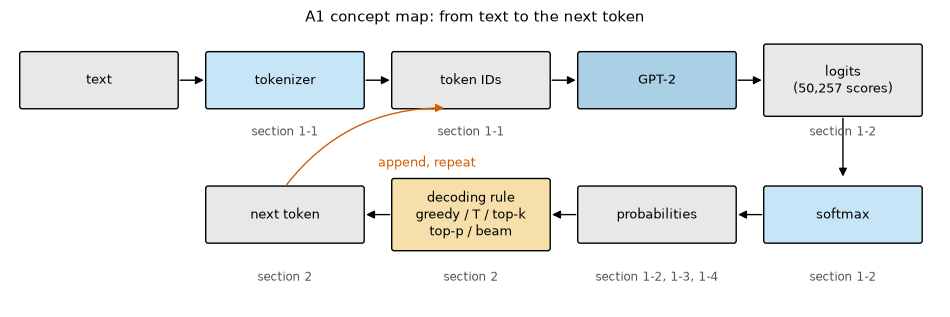

In [3]:
draw_concept_map()

**그림에서 볼 것**
- 위 줄: 글이 토큰 번호가 되고, GPT-2 가 어휘 50,257개 각각에 점수(logit)를 매깁니다.
- 아래 줄: 점수를 확률로 바꾸고, **디코딩 규칙**(주황)이 그중 하나를 고릅니다.
- 빨간 화살표: 고른 토큰을 글 뒤에 붙이고 처음부터 다시 돕니다. 글은 이렇게 한 토큰씩 자랍니다.

## 1. 먼저 알아 둘 것

### 1-1. 토큰과 토크나이저

**한 줄 정의**: **토큰**(token)은 모델이 읽는 글 조각이고, **토크나이저**(tokenizer)는 글을 토큰으로 자르고 번호를 붙이는 규칙입니다.
토큰 종류 전체 목록을 **어휘**(vocabulary)라고 하며, GPT-2 의 어휘는 50,257개입니다 [3].

**왜 필요한가**: 모델은 숫자만 계산합니다. 글자 하나씩 자르면 글이 너무 길어지고, 단어 단위로 자르면 처음 보는 단어를 다룰 수 없습니다.
그래서 자주 나오는 덩어리는 한 토큰으로, 드문 단어는 여러 조각으로 자르는 중간 방식(BPE, byte pair encoding)을 씁니다 [3][4].
GPT-2 는 이것을 글자가 아니라 **바이트** 단위로 해서, 어떤 글이든 어휘 밖으로 벗어나지 않게 했습니다 [3].

**숫자로 따라가기**: 아래 세 문장을 실제 GPT-2 토크나이저로 잘라 봅니다.

In [4]:
# (그림에 붙일 영어 이름, 문장)  그림 글꼴에 한글이 없을 수 있어 이름은 영어로 붙인다
examples = [("English sentence", "The class was about agents."),
            ("rare long word", "Antidisestablishmentarianism"),
            ("Korean, 3 words", "서당개 삼 년")]
rows = []
for label, s in examples:
    ids_s = tok(s).input_ids
    pieces = [t.replace("Ġ", "·") for t in tok.convert_ids_to_tokens(ids_s)]
    rows.append((label, list(zip(pieces, ids_s))))
    print(f"{s!r:35} -> {len(ids_s)} tokens: {pieces}")
assert len(tok) == 50257                         # GPT-2 어휘 크기 [3]
assert len("서".encode("utf-8")) == 3             # 한글 글자 하나는 UTF-8 로 3바이트

'The class was about agents.'       -> 6 tokens: ['The', '·class', '·was', '·about', '·agents', '.']
'Antidisestablishmentarianism'      -> 5 tokens: ['Ant', 'idis', 'establishment', 'arian', 'ism']
'서당개 삼 년'                           -> 14 tokens: ['ì', 'Ħ', 'ľ', 'ëĭ', '¹', 'ê', '°', 'ľ', '·ì', 'Ĥ', '¼', '·ë', 'ħ', 'Ħ']


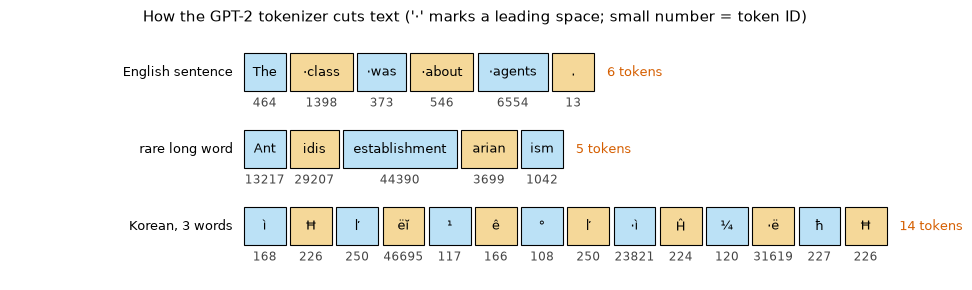

In [5]:
draw_tokens(rows)

**그림에서 볼 것**
- 영어 문장은 거의 단어마다 한 토큰입니다. `·` 표시는 "앞에 띄어쓰기가 붙은 토큰"이라는 뜻입니다(토크나이저 내부에서는 `Ġ` 로 씁니다).
- 드문 긴 단어는 여러 조각으로 잘립니다. 모델은 이 조각들을 이어 읽습니다.
- GPT-2 를 만든 사람들은 학습 글(WebText)에서 영어가 아닌 웹 문서를 일부러 뺐습니다 [3]. 그래서 한글 덩어리가 어휘에 거의 없고,
  한글은 UTF-8 에서 글자 하나가 3바이트라(위 `assert`) 글자 하나가 바이트 조각 여러 개로 쪼개집니다. 조각 문자열이 깨져 보이는 것은 바이트를 그대로 적었기 때문입니다.
  같은 뜻이라도 토큰이 많을수록 계산과 비용이 늘어납니다.

**식과 근거**: 바이트 단위 BPE 는 GPT-2 보고서 2.2절, 어휘 50,257개는 2.3절에 있습니다 [3]. BPE 는 Sennrich 등이 드문 단어를 다루려고 제안한 방법입니다 [4].
슬라이드 23쪽도 토크나이저를 더 읽을 거리로 소개합니다 [1].

**직접 바꿔 보기**: 아래 문장을 바꿔 실행해 보세요. 자기 이름, 유전자 이름(`BRCA1`), 숫자(`3.14159`)를 넣어 보면 재미있습니다.

In [6]:
my_text = "BRCA1 mutations in 3.14159 percent"
print([t.replace("Ġ", "·") for t in tok.tokenize(my_text)])

['B', 'RC', 'A', '1', '·mutations', '·in', '·3', '.', '14', '159', '·percent']


### 1-2. logit 과 softmax

**한 줄 정의**: **logit** 은 모델이 어휘의 토큰마다 매기는 점수(아무 실수)이고, **softmax** 는 그 점수를 합이 1인 확률로 바꾸는 함수입니다.

**왜 필요한가**: 점수는 음수도 될 수 있고 합도 제각각이라 그대로는 확률이 아닙니다.
softmax 는 점수마다 $e^{z}$ 를 계산해 모두 양수로 만든 뒤, 전체 합으로 나눠 합을 1로 맞춥니다.

**숫자로 따라가기**: 토큰 다섯 개의 점수가 아래와 같다고 합시다.

| 토큰 | logit $z$ | $e^{z}$ | 확률 $= e^{z} / 13.12$ |
|---|---|---|---|
| " to" | 2.0 | 7.39 | 0.563 |
| " the" | 1.0 | 2.72 | 0.207 |
| " a" | 0.5 | 1.65 | 0.126 |
| " how" | 0.0 | 1.00 | 0.076 |
| " cats" | −1.0 | 0.37 | 0.028 |

점수가 1 차이 나면 확률은 $e \approx 2.7$ 배 차이 납니다(" to" 와 " the": 0.563 ÷ 0.207 ≈ 2.7).

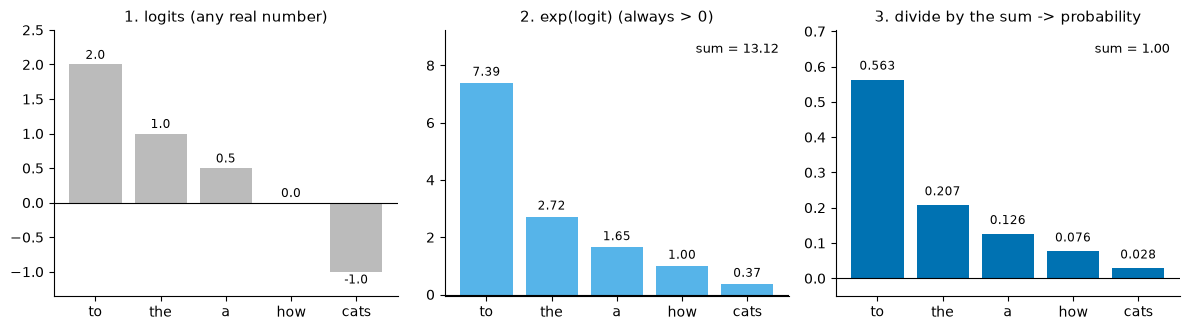

In [7]:
toy_labels = ["to", "the", "a", "how", "cats"]
toy_logits = [2.0, 1.0, 0.5, 0.0, -1.0]
draw_softmax_steps(toy_logits, toy_labels)

**그림에서 볼 것**
- 왼쪽: 점수는 음수(" cats" −1.0)도 있습니다.
- 가운데: $e^{z}$ 를 하면 모두 양수가 되고, 순서는 그대로입니다.
- 오른쪽: 합(13.12)으로 나누면 합이 1인 확률표가 됩니다.

**식과 근거**

$$P(\text{token}_i) = \frac{e^{z_i}}{\sum_j e^{z_j}}$$

다음 토큰 확률을 이렇게 logit 의 softmax 로 계산하는 것은 Holtzman 등의 식 (4)에서 $t = 1$ 인 경우입니다 [6].

**직접 바꿔 보기**: 위 셀의 `toy_logits` 에서 " to" 를 4.0 으로 올리거나, 모두 같은 값으로 바꿔 보세요. 모두 같으면 확률도 모두 0.2 가 됩니다.

이제 진짜 GPT-2 로 "The class was about" 다음 토큰의 확률표를 뽑습니다. 점수는 어휘 크기만큼, 즉 50,257개 나옵니다.
문장 앞에는 시작 표시 `<|endoftext|>` 를 붙입니다(왜 붙이는지는 1-4 에서). 붙이지 않은 경우와도 비교합니다.
GPT-2 에는 "문장 시작"만 뜻하는 토큰이 따로 없습니다. 이름 그대로 "글의 끝"을 뜻하는 `<|endoftext|>` 를 시작 표시로도 씁니다.
OpenAI 의 GPT-2 코드도 조건 없이 글을 만들 때 이 토큰에서 시작하고 [7], Hugging Face 에서는 시작(bos)과 끝(eos) 토큰이 둘 다 이것입니다(아래 `assert`).

토큰: ['<|endoftext|>', 'The', ' class', ' was', ' about']
P(' to'): 시작 표시 있음 0.3171 / 없음 0.1832


,token,slide 17,GPT-2 (this notebook)
0,' to',0.3171,0.3171
1,' as',0.0491,0.0491
2,' the',0.0360,0.0360
3,' a',0.0330,0.0330
4,' two',0.0147,0.0147
5,' how',0.0124,0.0124
6,' getting',0.0101,0.0101
7,' three',0.0100,0.0100
8,' time',0.0091,0.0091
9,"' ""'",0.0081,0.0081


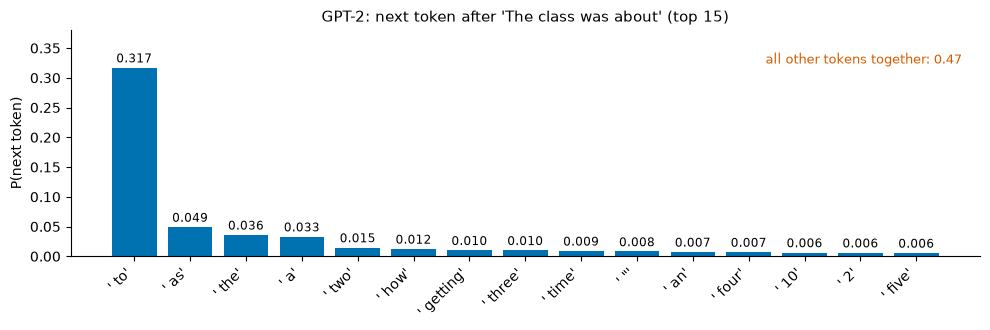

In [8]:
prompt = "The class was about"
ids = tok(tok.bos_token + prompt, return_tensors="pt").input_ids.to(device)
print("토큰:", [tok.decode(t) for t in ids[0]])

with torch.no_grad():
    logits = model(ids).logits[0, -1]          # 마지막 위치의 logit, 크기 50257
    logits_nobos = model(tok(prompt, return_tensors="pt").input_ids.to(device)).logits[0, -1]
probs = torch.softmax(logits, dim=-1)
assert tok.bos_token == tok.eos_token == "<|endoftext|>"     # 시작 표시 = 끝 표시
to_id = tok(" to").input_ids[0]
print(f"P(' to'): 시작 표시 있음 {probs[to_id]:.4f} / 없음 {torch.softmax(logits_nobos, -1)[to_id]:.4f}")

# 슬라이드 17쪽 표의 열 개와 나란히 놓고, 소수 넷째 자리까지 모두 같은지 확인한다
slide17 = [(" to", 0.3171), (" as", 0.0491), (" the", 0.036), (" a", 0.033), (" two", 0.0147),
           (" how", 0.0124), (" getting", 0.0101), (" three", 0.01), (" time", 0.0091), (' "', 0.0081)]
assert all(len(tok(t).input_ids) == 1 for t, _ in slide17)
ours = [probs[tok(t).input_ids[0]].item() for t, _ in slide17]
display(pd.DataFrame({"token": [repr(t) for t, _ in slide17], "slide 17": [v for _, v in slide17],
                      "GPT-2 (this notebook)": [round(o, 4) for o in ours]}))
assert all(abs(o - v) < 5e-5 for o, (_, v) in zip(ours, slide17))

top = torch.topk(probs, 15)
assert logits.shape[0] == len(tok)               # 어휘 크기만큼 점수가 나온다
assert abs(probs.sum().item() - 1) < 1e-4       # softmax 결과는 합이 1
draw_next_token_dist([repr(tok.decode(i)) for i in top.indices], top.values.cpu().numpy(),
                     1 - top.values.sum().item(), "GPT-2: next token after 'The class was about' (top 15)")

**그림에서 볼 것**
- 1등 " to" 가 0.32 로 가장 크지만, 15등 밖의 토큰 5만 개 넘게를 모두 합친 꼬리(오른쪽 위 빨간 숫자, 약 0.47)가 1등보다 큽니다.
  꼬리 토큰 하나하나는 작아도 모이면 큽니다. 2-3, 2-4 에서 꼬리를 자르는 이유가 이것입니다.
- 위 표처럼 슬라이드 17쪽의 열 개 숫자가 모두 소수 넷째 자리까지 같습니다(`assert` 로 확인) [1]. 슬라이드의 마지막 토큰은 둥근 따옴표(“)로 그려져 있고, GPT-2 토큰은 곧은 따옴표(")입니다.
  슬라이드에 모델 이름은 적혀 있지 않지만, 강의도 GPT-2 small 에 시작 표시를 붙여 계산한 것으로 보입니다.
- 시작 표시를 빼면 " to" 의 확률이 위에 찍힌 것처럼 크게 달라집니다(약 0.18). 같은 모델이라도 **입력 형식**이 확률을 바꿉니다.

### 1-3. 확률과 log 확률

**한 줄 정의**: **log 확률**은 확률에 자연로그($\ln$)를 씌운 값입니다. 0~1 사이 확률이 −∞~0 사이 음수로 바뀝니다.

**왜 필요한가**: 문장 확률은 토큰 확률을 계속 곱해서 구합니다(다음 절). 1보다 작은 수를 계속 곱하면 금방 너무 작아져서,
컴퓨터가 표현할 수 있는 가장 작은 수 아래로 내려가 **정확히 0** 이 됩니다(underflow). log 를 씌우면 곱이 덧셈이 되어 이 문제가 없습니다.

**숫자로 따라가기**

| 확률 $p$ | $\ln p$ |
|---|---|
| 0.5 | −0.69 |
| 0.1 | −2.30 |
| 0.0124 | −4.39 |

확률 0.1 인 토큰을 46개 곱하면 $10^{-46}$ 인데, 32비트 실수(float32)가 나타낼 수 있는 가장 작은 양수는 약 $1.4 \times 10^{-45}$ 이라 0 이 됩니다.
log 로는 $46 \times (-2.30) = -105.9$ 로 아무 문제 없습니다.

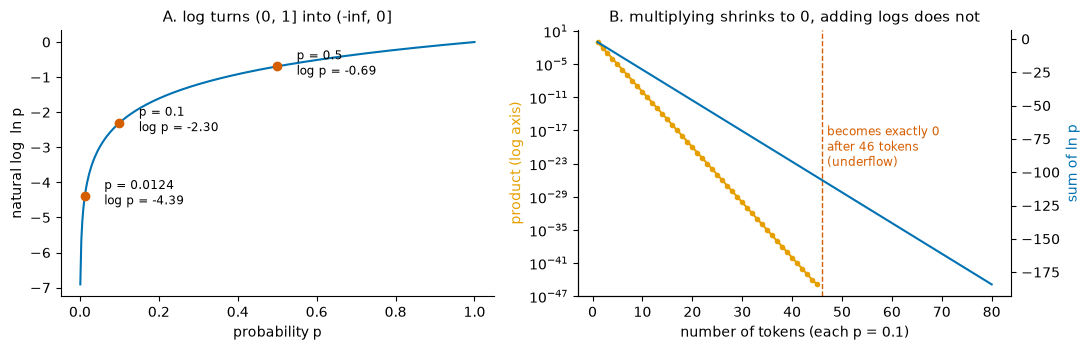

In [9]:
draw_log_prob()

**그림에서 볼 것**
- A: 확률이 1 이면 log 확률은 0, 확률이 작아질수록 log 확률은 빠르게 음수로 내려갑니다.
- B: 주황 점(곱)은 로그 눈금에서 일정하게 내려가다 어느 순간 사라집니다. 그 자리에서 정확히 0 이 된 것입니다. 파란 선(log 의 합)은 곧은 직선으로 계속 갑니다.

**식과 근거**: $\ln(a \times b) = \ln a + \ln b$ 라서 $\ln \prod_i p_i = \sum_i \ln p_i$ 입니다.
슬라이드 8쪽 각주도 실제로는 수치 안정성을 위해 확률 대신 확률의 log 를 더한다고 적습니다 [1].
0 이 되는 지점(46번째)은 이 노트북에서 float32 로 직접 계산한 결과입니다.

**직접 바꿔 보기**: 아래에서 토큰 확률과 개수를 바꿔 보세요.

In [10]:
p_tok, n_tok = 0.1, 46
print("float32 곱:", np.prod(np.full(n_tok, p_tok, dtype=np.float32)), "  log 합:", n_tok * math.log(p_tok))

float32 곱: 0.0   log 합: -105.91891427772609


### 1-4. 연쇄 법칙: 문장 확률은 조건부 확률의 곱

**한 줄 정의**: 문장 확률 = (첫 토큰의 확률) × (첫 토큰이 주어졌을 때 둘째 토큰의 확률) × ... 입니다. 이것을 **연쇄 법칙**(chain rule)이라고 합니다 [1].

**왜 필요한가**: 언어 모델은 "앞 토큰들이 주어졌을 때 다음 토큰의 확률"만 내놓습니다. 문장 전체의 확률은 이것을 차례로 곱해서 얻습니다.

**숫자로 따라가기**: "The class was about agents." 의 토큰마다 조건부 확률을 GPT-2 로 계산합니다.
첫 토큰의 확률을 구하려면 그 앞에 무언가 있어야 합니다. 그래서 1-2 처럼 맨 앞에 `<|endoftext|>` 를 붙입니다(GPT-2 에는 따로 "문장 시작" 토큰이 없음).

In [11]:
def token_logprobs(text):
    """문장의 토큰마다 log P(토큰 | 앞 토큰들)을 돌려준다."""
    ids = tok(tok.bos_token + text, return_tensors="pt").input_ids.to(device)
    with torch.no_grad():
        logp = torch.log_softmax(model(ids).logits[0, :-1], dim=-1)   # 위치 i 의 출력 = i+1 번째 토큰 예측
    target = ids[0, 1:]
    return logp[torch.arange(len(target)), target], [tok.decode(t) for t in target]

lp, toks = token_logprobs("The class was about agents.")
display(pd.DataFrame({"token": toks, "P(token | 앞)": lp.exp().cpu().numpy().round(4),
                      "log P": lp.cpu().numpy().round(2), "누적 log P": lp.cumsum(0).cpu().numpy().round(2)}))
print("문장 log 확률:", round(lp.sum().item(), 2), " 문장 확률:", f"{lp.sum().exp().item():.2e}")

,token,P(token | 앞),log P,누적 log P
0,The,0.0377,-3.28,-3.280000
1,class,0.0001,-8.96,-12.240000
2,was,0.0344,-3.37,-15.610000
3,about,0.0027,-5.90,-21.510000
4,agents,0.0000,-13.50,-35.009998
5,.,0.0252,-3.68,-38.689999


문장 log 확률: -38.69  문장 확률: 1.57e-17


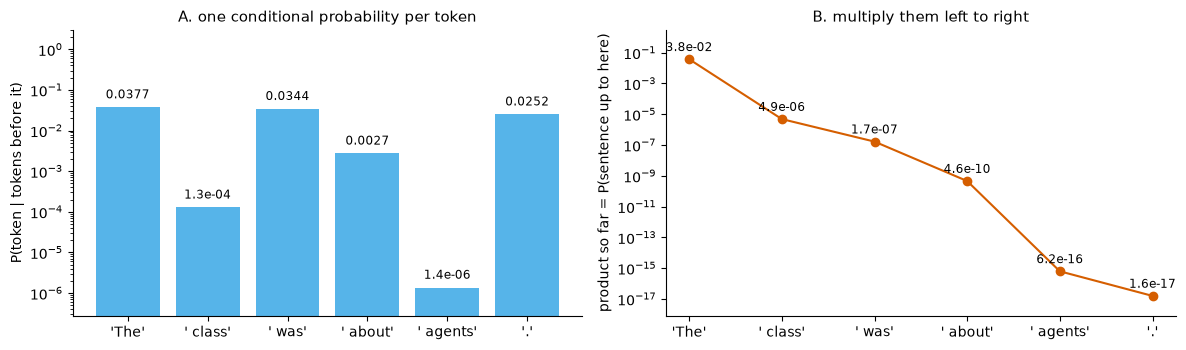

In [12]:
draw_chain_rule([repr(t) for t in toks], lp.exp().cpu().numpy())

**그림에서 볼 것**
- A: 토큰마다 조건부 확률이 하나씩 있습니다(로그 눈금). 앞 말에서 자연스럽게 이어지는 토큰일수록 막대가 높습니다.
- B: 그 값을 왼쪽부터 곱한 누적 확률입니다. 토큰이 늘 때마다 계속 작아집니다. 그래서 문장 확률 자체는 길이가 다른 문장끼리 비교하기 어렵습니다.
- 슬라이드 8쪽에 적힌 값 $P(\text{The}) = 0.0377$, $P(\text{class} \mid \text{The}) = 0.0001$, $0.0344$, $0.0252$ 가 위 표와 같습니다 [1].
  슬라이드의 최종 곱 $1.2 \times 10^{-17}$ 이 위 계산($1.6 \times 10^{-17}$ 근처)과 조금 다른 것은, " class" 의 확률(약 0.00013)을 0.0001 로 반올림해 곱했기 때문으로 보입니다($1.57 \times 10^{-17} \times 0.0001 / 0.000129 \approx 1.2 \times 10^{-17}$).

**식과 근거** (슬라이드 7–8쪽 [1])

$$P(w_1, \dots, w_n) = \prod_{i=1}^{n} P(w_i \mid w_1, \dots, w_{i-1})$$

**확인**: Hugging Face 모델에 `labels` 를 주면 토큰 평균 손실(= 평균 −log 확률)을 돌려줍니다. 위에서 직접 더한 값과 같아야 합니다.

In [13]:
ids_s = tok(tok.bos_token + "The class was about agents.", return_tensors="pt").input_ids.to(device)
with torch.no_grad():
    hf_loss = model(ids_s, labels=ids_s).loss.item()
assert abs(-lp.mean().item() - hf_loss) < 1e-4
print("직접 계산:", round(-lp.mean().item(), 5), " Hugging Face:", round(hf_loss, 5))

직접 계산: 6.44879  Hugging Face: 6.44879


길이가 다른 문장을 비교할 때는 토큰 평균 log 확률을 쓰고, 이것을 지수로 바꾼 $\exp(-\text{평균 log P})$ 를 **perplexity** 라고 부릅니다.
정의는 "시험 글 확률의 역수를 토큰 수로 정규화한 값"이고, "평균적으로 몇 갈래 중 하나를 고르는 것만큼 헷갈리나"(가중 평균 가지 수)로도 해석합니다 [8].
예를 들어 매번 4개 중 하나를 똑같은 확률로 고른다면 perplexity 는 4 입니다.

In [14]:
assert abs(math.exp(-math.log(1 / 4)) - 4) < 1e-9          # 4개 중 하나를 똑같이 고르면 perplexity 4
for s in ["The class was about agents.", "The class was about agents and tools and how they work."]:
    lp_s, _ = token_logprobs(s)
    print(f"{s!r:60} 토큰 {len(lp_s):2d}개  문장 확률 {lp_s.sum().exp().item():.2e}  perplexity {math.exp(-lp_s.mean().item()):.1f}")

'The class was about agents.'                                토큰  6개  문장 확률 1.57e-17  perplexity 631.9
'The class was about agents and tools and how they work.'    토큰 12개  문장 확률 1.53e-24  perplexity 96.5


**직접 바꿔 보기**: 위 목록에 문법이 틀린 문장(예: "Class the about was agents.")을 넣어 perplexity 가 어떻게 바뀌는지 보세요.

### 1-5. 생성 모델과 판별 모델

**한 줄 정의**: **판별 모델**(discriminative)은 입력 $x$ 가 주어졌을 때 답(라벨)의 확률 $P(y \mid x)$ 만 배웁니다.
**생성 모델**(generative)은 데이터 자체가 어떻게 생겼는지, 즉 $P(x)$ 를 배웁니다 [1].

**왜 필요한가**: 생성 모델은 배운 분포에서 **새 데이터를 뽑을 수 있습니다**. 언어 모델이 글을 쓸 수 있는 이유가 이것입니다 [1].
슬라이드는 생성 모델의 예로 Naive Bayes 와 diffusion 모델을, 판별 모델의 예로 logistic regression 과 SVM 을 듭니다 [1].

**숫자로 따라가기**: 두 무리(A, B)의 점이 있습니다. 판별 모델은 둘을 가르는 선 하나를 배웁니다.
생성 모델은 무리마다 "가운데가 어디이고 얼마나 퍼졌나"를 배워서, 그 분포에서 새 점을 뽑습니다.

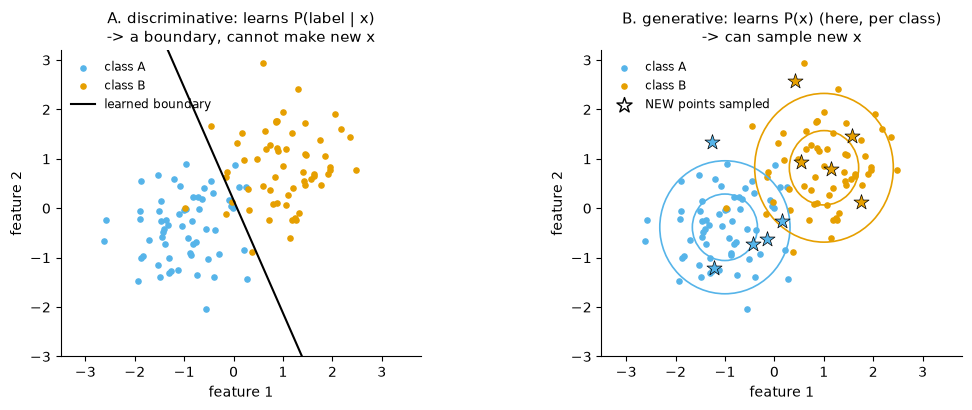

In [15]:
draw_gen_vs_disc()

**그림에서 볼 것**
- A(판별): 검은 선이 배운 전부입니다. 새 점이 들어오면 A 인지 B 인지는 말해 주지만, A 처럼 생긴 점을 새로 만들지는 못합니다.
- B(생성): 타원은 배운 분포(1, 2 표준편차)이고, 별은 그 분포에서 새로 뽑은 점입니다.
- 언어 모델은 B 쪽입니다. 토큰열의 분포 $P(w_1, \dots, w_n)$ 를 배웠으므로 그 분포에서 새 문장을 뽑을 수 있습니다(슬라이드 12–13쪽 [1]).

**식과 근거**: 판별은 $P(y \mid x)$, 생성은 $P(x)$ (또는 $P(x, y)$). 그림의 두 모델은 이 노트북에서 만든 장난감 예입니다.

## 2. 다음 토큰 고르기 (디코딩, 슬라이드 14–22쪽 [1])

확률표를 얻은 다음 실제로 토큰 하나를 골라야 글이 이어집니다. 고르는 규칙을 **디코딩 방법**이라고 합니다.

| 방법 | 하는 일 | 절 |
|---|---|---|
| greedy | 늘 확률이 가장 큰 토큰을 고른다 | 2-1 |
| 샘플링 + temperature $T$ | logit 을 $T$ 로 나눈 뒤 softmax 해서, 그 확률대로 무작위로 뽑는다 | 2-2 |
| top-k | 확률이 큰 $k$ 개만 남기고 다시 합을 1로 맞춘 뒤 뽑는다 | 2-3 |
| top-p | 큰 순서로 더해 누적 확률이 $p$ 에 이르는 가장 작은 묶음만 남긴다 | 2-4 |
| beam search | 후보 문장 $B$ 개를 함께 키우며 문장 전체 확률이 큰 것을 남긴다 | 2-5 |

**이 노트북의 생성 조건**: 2절의 모든 생성과 점수 계산은 1-2 처럼 문장 앞에 `<|endoftext|>` 를 붙인 상태로 합니다.
시작 표시가 확률을 바꾸므로(1-2 에서 " to" 0.18 → 0.32), 조건을 섞으면 점수를 서로 비교할 수 없습니다.

### 2-1. greedy 와 샘플링

**한 줄 정의**: **greedy** 는 매번 확률이 가장 큰 토큰을 고릅니다. **샘플링**은 확률에 비례해 무작위로 고릅니다.

**왜 필요한가**: greedy 는 늘 같은 답이 나오고 빠릅니다. 하지만 확률을 최대로 하는 방식은 열린 글쓰기에서 뻔하고 반복되는 글을 만든다는 보고가 있습니다 [6].
샘플링은 다양한 답을 내지만, 꼬리의 엉뚱한 토큰도 가끔 뽑힙니다. 2-2 ~ 2-4 의 방법은 이 꼬리를 다루는 방법입니다.

**숫자로 따라가기**: 1-2 의 장난감 확률표(" to" 0.563, ...)에서 greedy 는 늘 " to" 를 고릅니다.
샘플링을 1,000번 하면 " to" 는 평균 563번 나옵니다. 실제 한 번의 1,000번은 무작위라서 그보다 조금 많거나 적습니다.

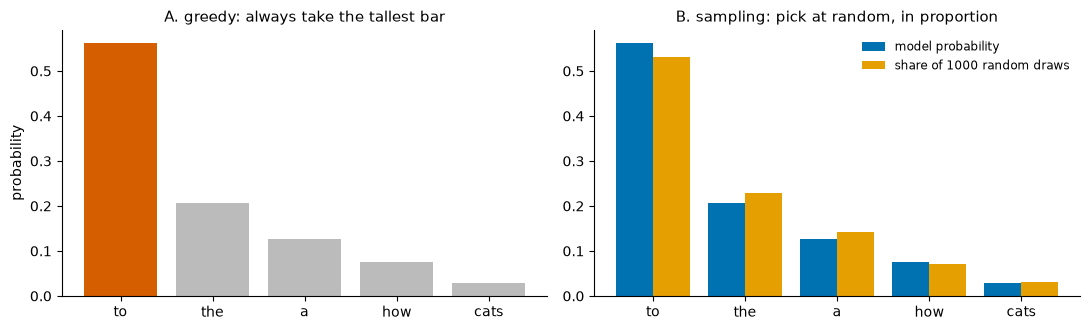

In [16]:
toy_probs = np.exp(toy_logits) / np.exp(toy_logits).sum()
draw_greedy_vs_sample(toy_labels, toy_probs)

**그림에서 볼 것**
- A: greedy 는 빨간 막대(가장 큰 확률)만 고릅니다. 나머지는 영영 안 나옵니다.
- B: 무작위로 1,000번 뽑으면 뽑힌 비율(주황)이 모델 확률(파랑)과 거의 같습니다. 확률 0.028 인 " cats" 도 가끔 나옵니다.

### 2-2. temperature

**한 줄 정의**: logit 을 온도 $T$ 로 나눈 뒤 softmax 합니다. $T < 1$ 이면 큰 확률이 더 커지고, $T > 1$ 이면 고르게 펴집니다 [6].

**왜 필요한가**: 같은 모델로 "무난하게"(낮은 $T$) 또는 "다양하게"(높은 $T$) 쓰게 조절하는 손잡이입니다.
슬라이드 22쪽은 수학·코드처럼 답이 정해진 일에는 낮은 온도, 창작에는 높은 다양성이 나을 수 있다고 정리합니다 [1].

**숫자로 따라가기**: 같은 장난감 logit [2.0, 1.0, 0.5, 0.0, −1.0] 에서 " to" 의 확률은
$T = 0.5$ 에서 0.83, $T = 1$ 에서 0.56, $T = 2$ 에서 0.37 입니다.

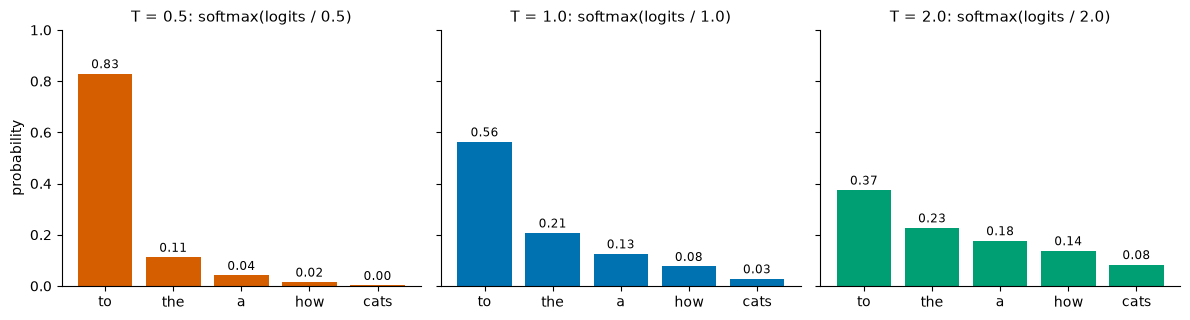

In [17]:
draw_temperature(toy_logits, toy_labels)

**그림에서 볼 것**
- $T = 0.5$(빨강): 1등이 거의 다 가져갑니다. $T \to 0$ 이면 greedy 와 같아집니다.
- $T = 2$(초록): 막대 높이가 비슷해집니다. 꼬리 토큰(" cats")이 뽑힐 확률이 0.03 에서 0.08 로 커집니다.
- 막대의 **순서**는 세 그림이 같습니다. 온도는 순서를 바꾸지 않고 차이만 키우거나 줄입니다.

**식과 근거**: $P_T(\text{token}_i) = e^{z_i / T} / \sum_j e^{z_j / T}$ (Holtzman 등 식 (4) [6]).
슬라이드 20쪽은 이것을 "확률을 $T$ 로 나눈 뒤 다시 합을 1로 맞춘다"고 짧게 적었지만 [1], 정의는 확률이 아니라 **logit** 을 나누는 것입니다 [6].
확률을 $T$ 로 나누고 다시 합을 1로 맞추면 원래 확률표로 돌아오므로 아무 효과가 없습니다.
다만 **log 확률**을 $T$ 로 나눈 뒤 다시 합을 1로 맞추면 logit 을 나눈 것과 같습니다. $\log p = z - (\text{모든 토큰에 같은 상수})$ 이고, 상수는 softmax 에서 사라지기 때문입니다.
그래서 슬라이드는 틀렸다기보다 "log" 를 빼고 짧게 쓴 것으로 볼 수 있습니다.

In [18]:
def apply_temperature(logits, T):
    return logits / T

# 확률을 T 로 나누고 다시 합을 1로 맞추면 원래대로 돌아온다 -> logit 을 나눠야 효과가 있다
pp = torch.softmax(torch.tensor(toy_logits), -1)
assert torch.allclose((pp / 2) / (pp / 2).sum(), pp)                    # 확률을 나누면: 효과 없음
assert torch.allclose(torch.softmax(torch.log(pp) / 2, -1),
                      torch.softmax(torch.tensor(toy_logits) / 2, -1))  # log 확률을 나누면: logit 을 나눈 것과 같음
assert not torch.allclose(torch.softmax(apply_temperature(torch.tensor(toy_logits), 2), -1), pp)

진짜 GPT-2 확률표에서는 어떻게 바뀌는지, 확률이 큰 순서(순위)를 가로축에, 확률을 세로축에 두고 봅니다(둘 다 로그 눈금).

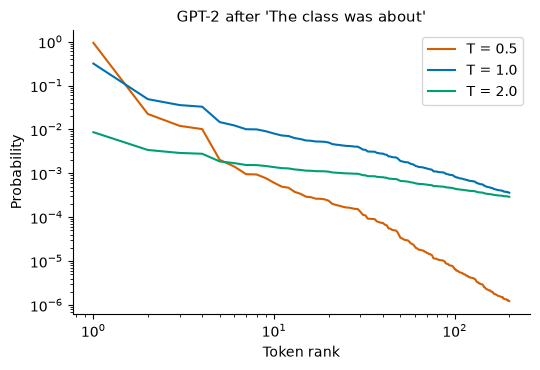

In [19]:
plt.figure(figsize=(5.5, 3.8))
for T, col in [(0.5, C["red"]), (1.0, C["blue"]), (2.0, C["green"])]:
    pr = torch.softmax(apply_temperature(logits, T), -1).sort(descending=True).values[:200].cpu()
    plt.plot(np.arange(1, 201), pr, label=f"T = {T}", color=col)
plt.yscale("log"); plt.xscale("log")
plt.xlabel("Token rank"); plt.ylabel("Probability")
plt.title("GPT-2 after 'The class was about'")
plt.legend(); plt.tight_layout(); plt.show()

**그림에서 볼 것**: $T$ 가 작을수록(빨강) 선이 가파릅니다. 1등이 더 크고 꼬리는 더 작습니다. $T$ 가 클수록(초록) 선이 평평해 꼬리 토큰이 많이 살아납니다.

**직접 바꿔 보기**: 위 셀의 온도 목록에 0.1 이나 5.0 을 넣어 보세요.

### 2-3. top-k

**한 줄 정의**: 확률이 큰 $k$ 개만 남기고 나머지는 0 으로 만든 뒤, 남은 것의 합이 1이 되게 다시 나눕니다 [5].

**왜 필요한가**: 꼬리에 있는 수만 개 토큰은 하나하나는 작아도 합치면 꽤 큰 확률이 되어, 샘플링 때 엉뚱한 말이 섞입니다.
Fan 등은 이야기 생성에서 상위 $k = 10$ 개 중에서만 뽑는 방식을 썼고, beam search 보다 훨씬 낫다고 보고했습니다 [5].

**숫자로 따라가기**: 확률 [0.40, 0.25, 0.15, 0.08, 0.05, 0.04, 0.02, 0.01] 에서 $k = 3$ 이면 [0.40, 0.25, 0.15] 만 남고,
합 0.80 으로 나눠 [0.50, 0.31, 0.19] 가 됩니다.

### 2-4. top-p (nucleus)

**한 줄 정의**: 확률이 큰 순서로 더해 가다가 누적 합이 $p$ 에 처음 이르는 **가장 작은 묶음**만 남깁니다 [6].

**왜 필요한가**: $k$ 를 하나로 정해 두면, 확률이 한 토큰에 몰린 경우에는 너무 많이 남기고, 고르게 퍼진 경우에는 너무 적게 남깁니다 [6].
top-p 는 분포 모양에 따라 남는 개수가 저절로 늘고 줄어듭니다.

**숫자로 따라가기**: 같은 확률에서 $p = 0.9$ 이면 누적 합이 0.40, 0.65, 0.80, 0.88, **0.93** 이므로 다섯 개가 남습니다.

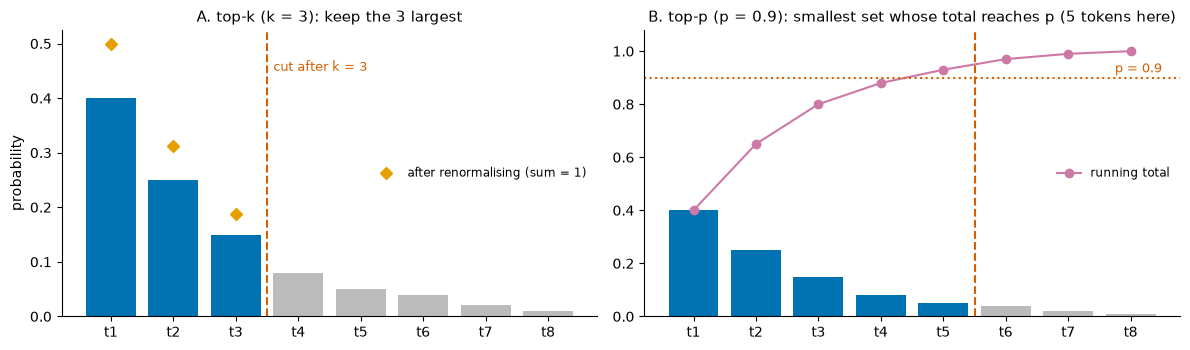

In [20]:
toy8_labels = ["t1", "t2", "t3", "t4", "t5", "t6", "t7", "t8"]
toy8 = [0.40, 0.25, 0.15, 0.08, 0.05, 0.04, 0.02, 0.01]
draw_topk_topp(toy8_labels, toy8, k=3, p=0.9)

**그림에서 볼 것**
- A(top-k): 파란 막대 세 개만 남고, 주황 다이아몬드가 다시 나눈 확률입니다(합 1).
- B(top-p): 보라 선이 누적 합입니다. 점선 $p = 0.9$ 를 처음 넘는 다섯 번째 토큰까지 남습니다.

**식과 근거**: top-p 의 남는 묶음 $V^{(p)}$ 는 $\sum_{x \in V^{(p)}} P(x \mid \text{앞}) \ge p$ 를 만족하는 가장 작은 집합입니다 (Holtzman 등 식 (2) [6]).

이제 확률표를 바꾸는 함수 두 개를 짭니다.

In [21]:
def top_k_filter(logits, k):
    kth = torch.topk(logits, k).values[..., -1, None]
    return logits.masked_fill(logits < kth, float("-inf"))

def top_p_filter(logits, p):
    sorted_logits, order = torch.sort(logits, descending=True)
    cum = torch.softmax(sorted_logits, dim=-1).cumsum(-1)
    remove = cum > p
    remove[..., 1:] = remove[..., :-1].clone()   # 누적이 p를 처음 넘는 토큰까지는 남긴다
    remove[..., 0] = False
    return logits.masked_fill(remove.scatter(-1, order, remove), float("-inf"))

**확인 1.** top-p 로 남긴 토큰들의 확률 합은 $p$ 이상이어야 하고, 그중 가장 작은 토큰 하나를 빼면 $p$ 아래로 내려가야 합니다(가장 작은 묶음).

In [22]:
p = 0.9
kept = torch.softmax(logits, -1)[top_p_filter(logits, p) > float("-inf")]
assert kept.sum() >= p and kept.sum() - kept.min() < p
print(f"top-p={p}: 남은 토큰 {len(kept)}개, 확률 합 {kept.sum():.3f}")

top-p=0.9: 남은 토큰 1514개, 확률 합 0.900


**확인 2.** Hugging Face 안에도 같은 일을 하는 부품(logits processor)이 있습니다. 결과가 같아야 합니다.

In [23]:
from transformers.generation.logits_process import TemperatureLogitsWarper, TopKLogitsWarper, TopPLogitsWarper

# float64(배정밀도)로 비교합니다. float32 에서는 누적 합을 더하는 순서(큰 것부터 / 작은 것부터)에 따른 반올림 차이로,
# 경계에 걸친 토큰 하나가 갈릴 수 있습니다. 이 노트북을 만들 때 실제로 " dogs" 하나(누적 0.9000013 자리)가 그랬습니다.
x = logits[None].double()
assert torch.equal(TopKLogitsWarper(50)(None, x.clone()), top_k_filter(x, 50))
assert torch.equal(TopPLogitsWarper(0.9)(None, x.clone()) > float("-inf"), top_p_filter(x, 0.9) > float("-inf"))
assert torch.allclose(TemperatureLogitsWarper(0.7)(None, x.clone()), apply_temperature(x, 0.7))
print("Hugging Face 부품과 같음")

Hugging Face 부품과 같음


**top-p 가 개수를 저절로 바꾸는 모습**: 다음 토큰이 거의 정해진 문장과, 아무 말이나 올 수 있는 문장을 비교합니다.

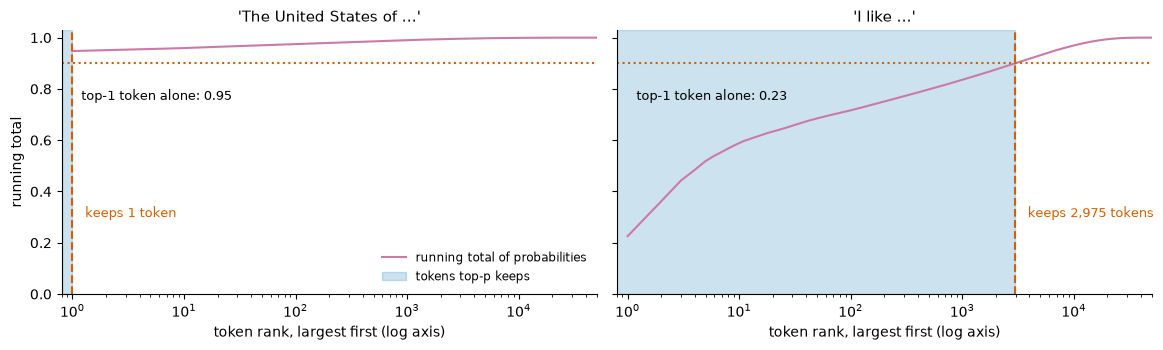

In [24]:
items = []
for ctx in ["The United States of", "I like"]:
    with torch.no_grad():
        z = model(tok(tok.bos_token + ctx, return_tensors="pt").input_ids.to(device)).logits[0, -1]   # 시작 표시를 붙인 조건
    items.append((ctx, torch.softmax(z, -1).sort(descending=True).values.cpu().numpy()))
draw_topp_contexts(items, p=0.9)
n_keep = [int(np.searchsorted(np.cumsum(ps), 0.9) + 1) for _, ps in items]
assert n_keep[0] < n_keep[1]          # 확률이 몰린 문장에서는 적게, 퍼진 문장에서는 많이 남는다

**그림에서 볼 것**
- 보라 선은 큰 확률부터 차례로 더한 누적 합이고, 파랗게 칠한 부분이 top-p 가 남기는 토큰입니다. 가로축은 로그 눈금입니다.
- 왼쪽(답이 거의 정해진 문장 "The United States of"): 1등 토큰 하나가 거의 다 가져가서, 아주 적은 수만으로 0.9 에 닿습니다.
- 오른쪽(무엇이든 올 수 있는 문장 "I like"): 확률이 고르게 퍼져서 선이 천천히 올라가고, 훨씬 많은 토큰이 남습니다.
- 처음에는 "The capital of France is" 를 골랐는데, GPT-2 small 은 이 문장 다음 토큰도 확신하지 못해서(1등 확률 약 0.08) 예로 맞지 않았습니다. 작은 모델은 사실을 잘 모릅니다.
- 같은 $k$ 를 두 문장에 쓰면 한쪽은 너무 많고 한쪽은 너무 적습니다. 이것이 top-p 를 제안한 이유입니다 [6].
  (남는 개수 자체는 이 노트북에서 GPT-2 로 계산한 결과입니다.)

**직접 바꿔 보기**: 위 셀의 두 문장을 바꾸거나 `p=0.5` 로 바꿔 보세요.

### 문장 이어 쓰기: 여러 설정 비교

위 부품을 이어 붙여 토큰을 하나씩 고르는 함수를 만듭니다. 매번 문장 전체를 다시 넣으므로 느리지만 원리가 잘 보입니다.
(매번 다시 계산하지 않는 방법인 KV 캐시는 A5 에서 다룹니다.)

In [25]:
def prompt_ids(text):
    """생성은 늘 시작 표시를 붙인 조건으로 (1-2 와 같은 조건)"""
    return tok(tok.bos_token + text, return_tensors="pt").input_ids.to(device)

def continuation_logprobs(full_ids, n_prompt):
    """full_ids = 시작 표시 + 프롬프트 + 생성 토큰. 생성된 토큰들의 log P(토큰 | 앞) 만 돌려준다."""
    with torch.no_grad():
        logp = torch.log_softmax(model(full_ids[None]).logits[0, :-1], -1)
    tgt = full_ids[1:]
    return logp[torch.arange(len(tgt)), tgt][n_prompt - 1:]

def generate(prompt, n_new=20, T=1.0, k=None, p=None, greedy=False, seed=0):
    g = torch.Generator(device=device).manual_seed(seed)
    ids = prompt_ids(prompt)
    for _ in range(n_new):
        with torch.no_grad():
            z = model(ids).logits[0, -1]
        if greedy:
            nxt = z.argmax()
        else:
            z = apply_temperature(z, T)
            if k: z = top_k_filter(z, k)
            if p: z = top_p_filter(z, p)
            nxt = torch.multinomial(torch.softmax(z, -1), 1, generator=g)[0]
        ids = torch.cat([ids, nxt.view(1, 1)], dim=1)
    return ids[0]

mine = generate(prompt, n_new=20, greedy=True)
with torch.no_grad():
    hf = model.generate(prompt_ids(prompt), max_new_tokens=20, do_sample=False, pad_token_id=tok.eos_token_id)[0]
assert torch.equal(mine, hf)       # 직접 짠 greedy = Hugging Face greedy
print("greedy:", tok.decode(mine, skip_special_tokens=True))

greedy: The class was about to be released, but it was already too late.

The class was about to be released


이제 설정마다 10번씩(토큰 15개씩) 뽑아 두 가지를 잽니다.

- **다양성**: 10개 글에 나온 "연속한 두 토큰 묶음" 중 서로 다른 것의 비율. 1에 가까울수록 글마다, 자리마다 다른 말을 했다는 뜻입니다(이 노트북에서 정한 잣대).
- **무난함**: 뽑힌 토큰들이 원래 모델($T = 1$, 자르기 없음)에서 받는 평균 log 확률. 높을수록 "모델이 보기에 흔한 말"입니다.

In [26]:
settings = {"T=0.3": dict(T=0.3), "T=0.7": dict(T=0.7), "T=1.0": dict(T=1.0), "T=1.5": dict(T=1.5),
            "top-k=10": dict(k=10), "top-p=0.9": dict(p=0.9)}
n_prompt = prompt_ids(prompt).shape[1]            # 시작 표시 + 프롬프트 토큰 수
rows = []
for name, kw in settings.items():
    outs = [generate(prompt, n_new=15, seed=s, **kw) for s in range(10)]
    lps = [continuation_logprobs(o, n_prompt).mean().item() for o in outs]
    pairs = [tuple(o[i:i + 2].tolist()) for o in outs for i in range(n_prompt, len(o) - 1)]
    rows.append({"setting": name,
                 "distinct 2-token pairs (share)": round(len(set(pairs)) / len(pairs), 2),
                 "mean log P per token": round(float(np.mean(lps)), 2),
                 "example": tok.decode(outs[0][n_prompt:])})
samp = pd.DataFrame(rows)
samp

,setting,distinct 2-token pairs (share),mean log P per token,example
0,T=0.3,0.55,-1.70,to be canceled.\n\nThe class was about to be ...
1,T=0.7,0.94,-2.63,"to end, and the stories of the ""tree"" were th..."
2,T=1.0,0.99,-4.33,"a week old when our stories broke in ""A Limou..."
3,T=1.5,1.00,-8.63,"along gritty pilot arcsave stories... is ""tre..."
4,top-k=10,0.91,-2.37,a week old when it was taken from the class r...
5,top-p=0.9,0.99,-4.12,"a week old when our stories broke in ""A Limou..."


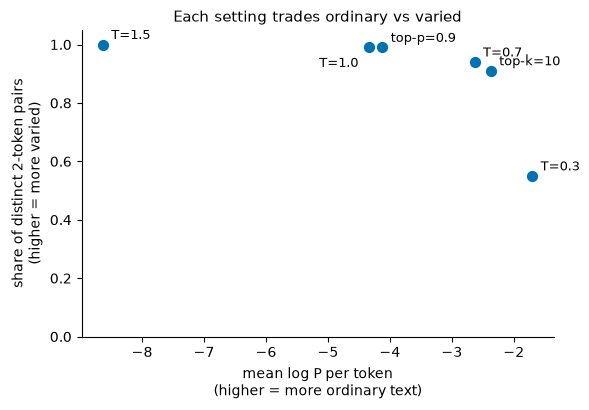

In [27]:
s = samp.set_index("setting")["mean log P per token"]
dv = samp.set_index("setting")["distinct 2-token pairs (share)"]
assert s["T=0.3"] > s["T=1.0"] > s["T=1.5"]          # 온도가 낮을수록 흔한 말을 고른다
assert dv["T=0.3"] < dv["T=1.5"]                     # 온도가 낮을수록 서로 비슷한 글이 나온다
draw_settings_scatter(samp)

**그림에서 볼 것** (이 노트북을 만들 때의 실행 결과 기준)
- $T = 0.3$ 은 오른쪽 아래입니다. 가장 무난하지만 두 토큰 묶음의 거의 절반이 되풀이되어, 10개 글이 서로 비슷합니다(표의 예시처럼 같은 말을 반복하기도 함).
- $T = 1.5$ 는 왼쪽 위입니다. 묶음이 모두 다르지만 평균 log 확률이 아주 낮아 엉뚱한 말이 많이 섞입니다.
- $T = 0.7$ 과 top-k = 10 은 무난함을 크게 잃지 않으면서 다양함이 0.9 이상이라, 둘 사이의 좋은 절충에 가깝습니다.
- top-p = 0.9 는 $T = 1.0$ 과 거의 같은 자리입니다. 이 프롬프트에서는 잘려 나가는 꼬리가 작아서 결과가 크게 바뀌지 않았습니다.
- 점의 위치는 씨앗(seed)을 고정한 10번 샘플링의 결과라, 같은 환경에서는 같고 다른 기계에서는 조금 달라질 수 있습니다.

### 2-5. beam search

**한 줄 정의**: 후보 문장 $B$ 개(beam)를 함께 들고 가면서, 매 걸음 "후보 × 다음 토큰" 조합 중 누적 log 확률이 큰 $B$ 개만 남깁니다 [9].
슬라이드 21쪽은 이것을 그림으로 소개합니다 [1]. 슬라이드 23쪽이 추천한 글 [9] 은 점수를 길이로 나누기도 하는데, 이 노트북은 나누지 않습니다(Hugging Face 의 `length_penalty=0.0` 과 같음).

**왜 필요한가**: greedy 는 지금 당장 1등만 봐서, 문장 전체로 보면 더 확률이 큰 문장을 놓칠 수 있습니다.
대신 후보를 $B$ 개 들고 다니므로 시간과 메모리가 더 듭니다 [1].

**숫자로 따라가기**: 첫 토큰이 "a"(0.5), "the"(0.4), "one"(0.1) 이고, "a" 다음은 많아야 0.4, "the" 다음 "dog" 는 0.9 라고 합시다.
greedy 는 "a" → "big" 으로 0.5 × 0.4 = 0.20 을 얻습니다. beam 2 개는 "a" 와 "the" 를 둘 다 들고 가서 "the dog" 0.4 × 0.9 = **0.36** 을 찾습니다.

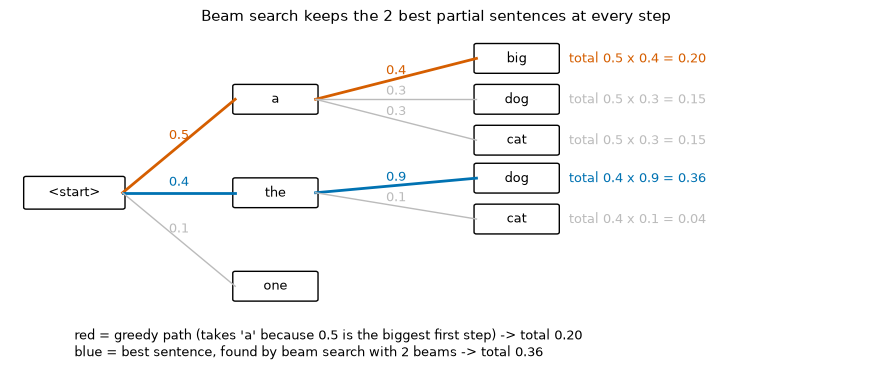

In [28]:
draw_beam_tree()

**그림에서 볼 것**
- 빨간 길(greedy): 첫 걸음에서 가장 큰 0.5 를 골랐지만, 그 뒤 선택지가 고만고만해서 전체 0.20 에 그칩니다.
- 파란 길: 첫 걸음에서 2등이었던 "the" 가 다음 걸음에서 0.9 를 만나 전체 0.36 이 됩니다. beam 이 2 개라서 "the" 를 버리지 않고 들고 갔기 때문에 찾을 수 있었습니다.

**식과 근거**: 매 걸음 점수 = 지금까지의 log 확률 합. 나무 그림의 숫자는 설명용 장난감입니다.

이제 GPT-2 에서 직접 짜고 Hugging Face 의 beam search 와 맞춰 봅니다.

In [29]:
def beam_search(prompt, B=4, n_new=10):
    ids = prompt_ids(prompt)
    beams = [(ids, 0.0)]                       # (토큰들, 누적 log 확률)
    for _ in range(n_new):
        batch = torch.cat([b[0] for b in beams])
        with torch.no_grad():
            logp = torch.log_softmax(model(batch).logits[:, -1].float(), -1)
        scores = torch.tensor([b[1] for b in beams], device=device)[:, None] + logp
        best = torch.topk(scores.flatten(), B)
        beams = [(torch.cat([beams[i // logp.shape[1]][0], torch.tensor([[i % logp.shape[1]]], device=device)], 1), s.item())
                 for i, s in zip(best.indices.tolist(), best.values)]
    return beams[0]

b_ids, b_score = beam_search(prompt, B=4, n_new=10)
g_ids = generate(prompt, n_new=10, greedy=True)
g_score = continuation_logprobs(g_ids, n_prompt).sum().item()          # 같은 조건(시작 표시 포함)으로 점수
assert abs(continuation_logprobs(b_ids[0], n_prompt).sum().item() - b_score) < 1e-3   # 두 점수가 같은 잣대인지 확인
print("greedy:", repr(tok.decode(g_ids, skip_special_tokens=True)), f"log P = {g_score:.2f}")
print("beam  :", repr(tok.decode(b_ids[0], skip_special_tokens=True)), f"log P = {b_score:.2f}")

with torch.no_grad():
    hf_beam = model.generate(prompt_ids(prompt), max_new_tokens=10, num_beams=4,
                             do_sample=False, length_penalty=0.0, early_stopping=False, pad_token_id=tok.eos_token_id)[0]
print("HF beam:", repr(tok.decode(hf_beam, skip_special_tokens=True)))
assert torch.equal(b_ids[0], hf_beam)

greedy: 'The class was about to be released, but it was already too late' log P = -18.39
beam  : 'The class was about to begin.\n\nThe class was about to' log P = -11.81


HF beam: 'The class was about to begin.\n\nThe class was about to'


이번 예에서 beam 쪽 log 확률이 greedy 보다 크거나 같은지는 위 출력에서 확인하세요(이 노트북의 결과입니다). 늘 그렇다는 보장은 없습니다.
greedy 가 고른 길이 중간에 다른 후보들에게 밀려 버려질 수도 있기 때문입니다.

확률을 최대로 하는 방식(beam search 포함)은 열린 글쓰기에서 밋밋하고 반복되는 글을 만든다는 보고가 있고 [6],
Fan 등도 beam search 가 흔한 표현을 반복하는 경향이 있다고 적었습니다 [5]. 그래서 열린 글쓰기에는 보통 샘플링 계열을 씁니다.

## 연습 문제

1. $T$ 를 0 에 가깝게 줄이면 샘플링은 무엇과 같아지나요?
2. top-p 에서 $p = 1.0$ 이면 무슨 일이 생기나요?
3. 슬라이드 12쪽 질문: 토큰열의 확률을 모델링하는 언어 모델은 생성 모델인가요, 판별 모델인가요?
4. `generate` 에서 `T=0.7, p=0.9` 를 같이 쓰면 어떤 순서로 적용되나요? 순서를 바꾸면 결과가 달라질까요?
5. 한글 문장은 영어보다 토큰이 많이 나왔습니다. 같은 내용을 한글로 물으면 무엇이 더 드나요?

<details><summary>답 보기</summary>

1. greedy 와 같아집니다. logit 을 아주 작은 수로 나누면 가장 큰 logit 의 확률이 1 에 가까워집니다.
2. 아무것도 자르지 않습니다(부동소수 반올림 오차를 빼면). 누적 확률이 1 에 이르려면 모든 토큰이 필요합니다.
3. 생성 모델입니다. 토큰열 자체의 분포 $P(x)$ 를 모델링하므로 그 분포에서 새 문장을 뽑을 수 있습니다(슬라이드 13쪽).
4. temperature 다음 top-p 입니다. top-p 는 temperature 로 바뀐 확률표에서 누적 확률을 계산하므로, 순서를 바꾸면 남는 토큰 수가 달라집니다.
5. 토큰이 많으면 모델이 처리할 위치가 늘어 계산 시간이 늘고, 같은 길이 제한(GPT-2 는 1,024 토큰 [3]) 안에 담을 수 있는 내용이 줄어듭니다.
</details>

## 정리

- 글은 토크나이저가 자른 토큰 번호로 들어가고, 모델은 어휘 전체에 점수(logit)를 매깁니다. softmax 가 이것을 확률표로 바꿉니다.
- 문장 확률은 조건부 확률을 차례로 곱한 값이고, 계산은 log 를 더해서 합니다.
- 같은 모델이라도 디코딩 방법에 따라 답이 크게 달라집니다. 에이전트를 만들 때 temperature, top-p 는 직접 고르는 설정값입니다.

## 실제와 다른 점

- 여기서 짠 `generate` 와 `beam_search` 는 매번 문장 전체를 다시 계산합니다. 실제 구현은 KV 캐시로 앞부분 계산을 재사용합니다(A5).
- 생성·판별 모델 그림과 beam 나무는 설명용 장난감 숫자입니다.

## 출처

| 번호 | 출처 | 이 노트북에서 쓴 곳 |
|---|---|---|
| [1] | Yang, Ryan, Yang. CS329Z Engineering AI Agents, Lecture 2 "LLMs for Builders" 슬라이드 (Stanford, 2026). [PDF](https://web.stanford.edu/class/cs329z/slides/lecture02.pdf), 사본 `data/lecture02.pdf` | 7–8쪽 연쇄 법칙과 $P(\text{The})=0.0377$, 8쪽 각주(실제로는 log 를 더함), 10–13쪽 생성·판별 모델, 17쪽 다음 토큰 확률표, 20쪽 temperature, 21–22쪽 beam search 와 샘플링 고려 사항, 23쪽 읽을거리 |
| [2] | Michael Ryan. LLMs for Agent Builders, Stanford CS329Z Lecture 2 영상 (Stanford Online, 2026). [YouTube](https://www.youtube.com/watch?v=Vr1NzH8bT44) | 영상 구간 3:57, 7:46 |
| [3] | Radford, Wu, Child, Luan, Amodei, Sutskever. Language Models are Unsupervised Multitask Learners. OpenAI 기술 보고서 (2019). [PDF](https://cdn.openai.com/better-language-models/language_models_are_unsupervised_multitask_learners.pdf) | 바이트 단위 BPE(2.2절), 어휘 50,257개와 문맥 길이 1,024 토큰(2.3절), 학습 글에서 영어가 아닌 웹 문서를 일부러 뺐음(3.7절) |
| [4] | Sennrich, Haddow, Birch. Neural Machine Translation of Rare Words with Subword Units. ACL 2016. [arXiv:1508.07909](https://arxiv.org/abs/1508.07909) | BPE 로 드문 단어를 조각내 다루기 |
| [5] | Fan, Lewis, Dauphin. Hierarchical Neural Story Generation. ACL 2018, 889–898쪽. [arXiv:1805.04833](https://arxiv.org/abs/1805.04833) | top-k 샘플링($k = 10$, 5.4절), beam search 가 흔한 표현을 반복하는 경향 |
| [6] | Holtzman, Buys, Du, Forbes, Choi. The Curious Case of Neural Text Degeneration. ICLR 2020. [arXiv:1904.09751](https://arxiv.org/abs/1904.09751) | top-p 정의(식 2), temperature 식(식 4), 고정 $k$ 의 문제(3.2절), 확률 최대화 디코딩이 밋밋하고 반복되는 글을 만든다는 보고 |
| [7] | OpenAI. gpt-2 코드 저장소. [GitHub](https://github.com/openai/gpt-2), `src/generate_unconditional_samples.py` | 조건 없는 생성이 `<\|endoftext\|>` 토큰에서 시작함 (`start_token=enc.encoder['<\|endoftext\|>']`) |
| [8] | Jurafsky, Martin. Speech and Language Processing (3판 초고), 3장 N-gram Language Models (2026). [PDF](https://web.stanford.edu/~jurafsky/slp3/3.pdf) | 3.3절 perplexity 정의, 3.3.1절 가중 평균 가지 수 해석 |
| [9] | Labonne. Decoding Strategies in Large Language Models. Hugging Face 블로그 (2024). [링크](https://huggingface.co/blog/mlabonne/decoding-strategies) (슬라이드 23쪽 읽을거리) | beam search 의 점수 = 토큰 log 확률의 누적 합(글에서는 길이로 나누기도 함) |

숫자 결과(확률표, 남는 토큰 수, 설정별 다양성 등)는 출처가 아니라 이 노트북에서 GPT-2 로 직접 계산한 값입니다.